# 01 — Data, zero-shot behaviour and routing of the base model

Exploration done before writing the training code. Everything here reads files produced by
`scripts/prepare_data.py`, `scripts/evaluate.py` and `scripts/analyze_routing.py`, so the
notebook runs on CPU in a few seconds.

In [1]:
import sys, json, collections
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

from finmoe.data import TASKS, FIN_TASKS, load_split, format_prompt
from finmoe.selection import select_by_threshold, domain_specificity
pd.set_option("display.precision", 3)

/Users/peter/Documents/Khalifa uni/Deep Learning SD/MoE_project/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Datasets

In [2]:
rows = []
for task in FIN_TASKS + ("sst2",):
    for split in ("train", "val", "test"):
        path = ROOT / "data/splits" / f"{task}_{split}.jsonl"
        if not path.exists():
            continue
        data = load_split(ROOT / "data/splits", task, split)
        counts = collections.Counter(r["label"] for r in data)
        rows.append({"task": task, "split": split, "n": len(data),
                     "words (mean)": np.mean([len(r["text"].split()) for r in data]),
                     **{TASKS[task].labels[k]: v for k, v in sorted(counts.items())}})
pd.DataFrame(rows).fillna("")

/var/folders/6n/xcr_g_3d13529x7vjx2_z7qc0000gn/T/ipykernel_52478/2181645953.py:12: Pandas4Warning: 'str' is not supported as a fill value for float64 dtype. In a future version, calling fillna with an incompatible value will raise. Explicitly cast to a common dtype before filling.
  pd.DataFrame(rows).fillna("")


,task,split,n,words (mean),negative,neutral,positive,No,Yes
0,fpb,train,3100,23.103,382.0,1859.0,859.0,,
1,fpb,val,776,23.231,106.0,443.0,227.0,,
2,fpb,test,970,22.991,116.0,577.0,277.0,,
3,fiqasa,train,750,12.041,235.0,58.0,457.0,,
4,fiqasa,val,188,11.303,52.0,15.0,121.0,,
5,fiqasa,test,235,11.800,76.0,18.0,141.0,,
6,tfns,train,2500,12.196,368.0,1650.0,482.0,,
7,tfns,val,500,12.230,86.0,317.0,97.0,,
8,tfns,test,2388,12.322,347.0,1566.0,475.0,,
9,headlines,train,2500,38.041,,,,1701.0,799.0


The label distributions are skewed in different directions: FPB and TFNS are dominated by
*neutral*, FiQA-SA by *positive* and has very few neutral examples. Accuracy alone would
reward predicting the majority class, so macro-F1 is the main metric.

In [3]:
example = load_split(ROOT / "data/splits", "fpb", "train")[0]
print(format_prompt(TASKS["fpb"], example["text"]), TASKS["fpb"].labels[example["label"]])
print("---")
example = load_split(ROOT / "data/splits", "headlines", "train")[0]
print(format_prompt(TASKS["headlines"], example["text"]), TASKS["headlines"].labels[example["label"]])

Classify the sentiment of the sentence from a financial news article as negative, neutral or positive.
Text: The five-storey , eco-efficient building will have a gross floor area of about 15,000 sq m. It will also include apartments .
Answer: neutral
---
Look for any mention of future gold prices. Does the news headline suggest a Direction Up for gold? Your response should be Yes or No.
Text: feb gold up 60c at $423.60/oz in ny
Answer:
Answer: Yes


## 2. Zero-shot predictions of the base model

In [4]:
res = json.load(open(ROOT / "results/eval/base_0shot_test.json"))
pd.DataFrame(res["metrics"]).T[["accuracy", "macro_f1"]]

,accuracy,macro_f1
fiqasa,0.706,0.519
fpb,0.376,0.373
headlines,0.632,0.455
sst2,0.932,0.932
tfns,0.333,0.335
mean,0.512,0.420


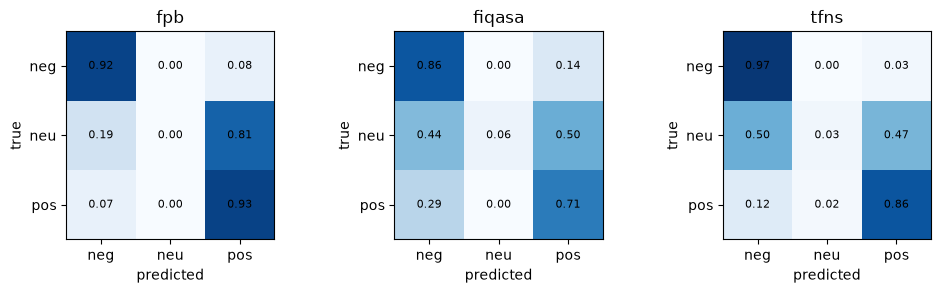

In [5]:
preds = [json.loads(l) for l in open(ROOT / "results/eval/base_0shot_test.predictions.jsonl")]
fig, axes = plt.subplots(1, 3, figsize=(10, 3))
for ax, task in zip(axes, ["fpb", "fiqasa", "tfns"]):
    y = [p["label"] for p in preds if p["task"] == task]
    yhat = [p["pred"] for p in preds if p["task"] == task]
    cm = confusion_matrix(y, yhat, labels=[0, 1, 2], normalize="true")
    ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)
    for i in range(3):
        for j in range(3):
            ax.text(j, i, f"{cm[i, j]:.2f}", ha="center", va="center", fontsize=8)
    ax.set_xticks(range(3), ["neg", "neu", "pos"]); ax.set_yticks(range(3), ["neg", "neu", "pos"])
    ax.set_title(task); ax.set_xlabel("predicted"); ax.set_ylabel("true")
plt.tight_layout()

The base model almost never answers *neutral*: neutral financial statements ("the company
will hold its AGM on ...") are pushed to positive or negative. The same model reaches
93% on SST-2, so the problem is the domain's notion of sentiment, not the format.

## 3. Routing of the base model

24 MoE layers x 32 experts, top-k = 8


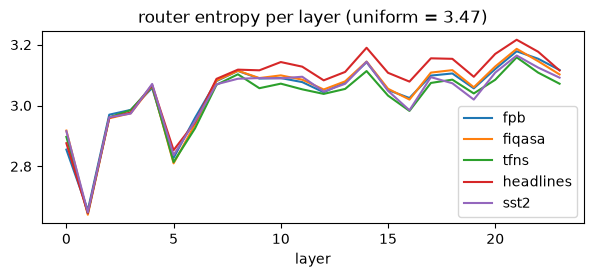

In [6]:
base = torch.load(ROOT / "results/routing/base_train.pt", weights_only=False)["tasks"]
layers, experts = base["fpb"]["selection_ratio"].shape
print(f"{layers} MoE layers x {experts} experts, top-k = 8")
ent = pd.DataFrame({t: base[t]["entropy"].numpy() for t in base})
ax = ent.plot(figsize=(7, 2.5), title="router entropy per layer (uniform = %.2f)" % np.log(experts))
ax.set_xlabel("layer");

In [7]:
def js(p, q):
    m = (p + q) / 2
    kl = lambda a, b: (a * (a.clamp_min(1e-12) / b.clamp_min(1e-12)).log()).sum(-1)
    return ((kl(p, m) + kl(q, m)) / 2).mean().item()

tasks = list(base)
pd.DataFrame([[1000 * js(base[a]["selection_ratio"], base[b]["selection_ratio"]) for b in tasks] for a in tasks],
             index=tasks, columns=tasks).round(1)

,fpb,fiqasa,tfns,headlines,sst2
fpb,0.0,3.5,4.8,12.6,11.9
fiqasa,3.5,0.0,2.4,14.2,13.5
tfns,4.8,2.4,0.0,18.4,16.4
headlines,12.6,14.2,18.4,0.0,12.8
sst2,11.9,13.5,16.4,12.8,0.0


The three sentiment datasets route very similarly to each other (JS ~ 2-5e-3) and clearly
differently from SST-2 (12-16e-3), even though SST-2 is the same task. Headlines differs from
everything: different task *and* a long templated question in the prompt.

## 4. How many experts would ESFT select?

In [8]:
stats = torch.load(ROOT / "results/routing/esft_stats.pt", weights_only=False)
rows = []
for score in ("selection_ratio", "mean_prob"):
    for p in (0.1, 0.2, 0.3):
        chosen = select_by_threshold(stats[score], p)
        n = sum(len(v) for v in chosen.values())
        rows.append({"score": score, "p": p, "experts": n, "share of all experts": n / (layers * experts),
                     "trainable params (M)": n * (1024 * 1024 + 1024 * 512) / 1e6})
pd.DataFrame(rows)

,score,p,experts,share of all experts,trainable params (M)
0,selection_ratio,0.1,43,0.056,67.633
1,selection_ratio,0.2,82,0.107,128.975
2,selection_ratio,0.3,128,0.167,201.327
3,mean_prob,0.1,51,0.066,80.216
4,mean_prob,0.2,100,0.130,157.286
5,mean_prob,0.3,153,0.199,240.648


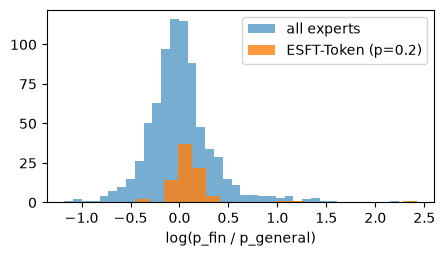

In [9]:
spec = domain_specificity(stats["selection_ratio"], stats["general_selection_ratio"])
chosen = select_by_threshold(stats["selection_ratio"], 0.2)
picked = torch.cat([spec[l, e] for l, e in chosen.items()])
plt.figure(figsize=(5, 2.5))
plt.hist(spec.flatten().numpy(), bins=40, alpha=0.6, label="all experts")
plt.hist(picked.numpy(), bins=20, alpha=0.8, label="ESFT-Token (p=0.2)")
plt.xlabel("log(p_fin / p_general)"); plt.legend();

The experts that ESFT picks by usage frequency are only weakly domain-specific: their mean
log-ratio is 0.12, against 0.69 for the 82 most domain-specific experts. They are the
high-traffic experts (6.7% of routing decisions each vs. 3.1% on average) that are busy on any
text. This motivated the `esft_specific` variant: same budget, experts ranked by domain
specificity. The trade-off is that those experts see fewer tokens (2.7% each).